# DS2002 · Midterm Progress

**Lab — 2026-10-30 · Fall 2026**  

---

## Lab 10 — Midterm progress, week 2 of 3

One submission per team. Questions 1 through 3 should be substantially answered by now — not polished, but answered, with a number and a chart each.

Presentations are Monday. If a question is not working, this is the last checkpoint where there is time to do something about it, so report the actual state rather than the intended one.

### Q1 — Demand surge

Baseline: **September 1–4, 2024**, 1,089 positive reported units/day. Observed surge: **September 10–14**, 3,190/day, **2.929× baseline (+192.9%)**. Actual pre-landfall comparison: **September 19–25**, 1,107.4/day, **1.017× (+1.7%)**. All boundaries are inclusive. The early window is descriptive and selected from the observed spike; it does not establish hurricane causation. Charts below include the daily series and top five categories.

In [5]:
# Load only the required team sections so this checkpoint is reproducible.
import json
from pathlib import Path
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data/walmart_transactions.csv").is_file())
team = json.loads((root / "notebooks/team_notebook.ipynb").read_text())
def run_team_cells(indices):
    for i in indices:
        assert team["cells"][i]["cell_type"] == "code"
        exec(compile("".join(team["cells"][i]["source"]), f"team_cell_{i}", "exec"), globals())
run_team_cells([1, 2, 16])
display(q1_summary.round(3))

Original transactions: 25562
Store reference rows: 14
Original transactions: 25562
Cleaned transactions: 25532
Rows removed: 30
Unique cleaned stores: 12
Original category labels: 37
Cleaned category labels: 10

Cleaning decision log:


,dataset,step,before,after,affected
0,transactions,Remove exact duplicates,25562,25532,30
1,transactions,Standardize store IDs,25532,25532,4345
2,transactions,Parse nonmissing timestamps,25532,25532,24648
3,transactions,Flag missing / unparseable timestamps,25532,25532,884
4,transactions,Create daily date keys,25532,25532,24648
5,transactions,Clean formatted unit prices,25532,25532,4329
6,transactions,Flag missing/unparseable unit prices,25532,25532,0
7,transactions,Flag negative quantities,25532,25532,130
8,transactions,Flag missing/unparseable quantities,25532,25532,0
9,transactions,Standardize SKU formatting,25532,25532,0



All initial cleaning checks passed!

First sales date: 2024-09-01
Last sales date: 2024-09-30
Peak daily order date: 2024-09-14
Peak daily transaction records: 2007


,start,end,days,positive_units_per_day,net_units_per_day,multiple,change_pct,net_multiple
window,,,,,,,,
Baseline,2024-09-01,2024-09-04,4,1089.000,1084.500,1.000,0.000,1.000
Observed surge,2024-09-10,2024-09-14,5,3190.000,3175.800,2.929,192.929,2.928
Pre-landfall,2024-09-19,2024-09-25,7,1107.429,1101.857,1.017,1.692,1.016


Undated rows excluded: 884
Dated nonpositive rows excluded from gross demand: 127
Peak: 2024-09-14 with 3958 positive units
Surge multiple using Sept 1–7 baseline: 2.492
Top five categories ranked by additional reported units/day:


,Baseline,Observed surge,Pre-landfall,extra_units_per_day,multiple
category_clean,,,,,
Emergency,352.00,1196.8,361.00,844.80,3.40
Breakfast,71.50,464.8,71.43,393.30,6.50
Entertainment,91.75,267.6,99.86,175.85,2.92
Grocery,176.25,344.4,172.00,168.15,1.95
Electronics,70.00,208.0,71.43,138.00,2.97


,start,end,days,positive_units_per_day,net_units_per_day,multiple,change_pct,net_multiple
window,,,,,,,,
Baseline,2024-09-01,2024-09-04,4,1089.000,1084.500,1.000,0.000,1.000
Observed surge,2024-09-10,2024-09-14,5,3190.000,3175.800,2.929,192.929,2.928
Pre-landfall,2024-09-19,2024-09-25,7,1107.429,1101.857,1.017,1.692,1.016


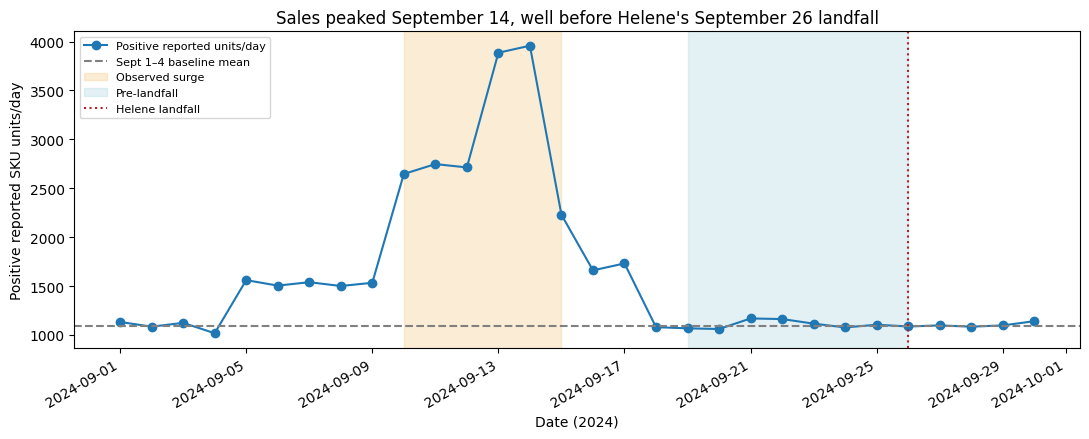

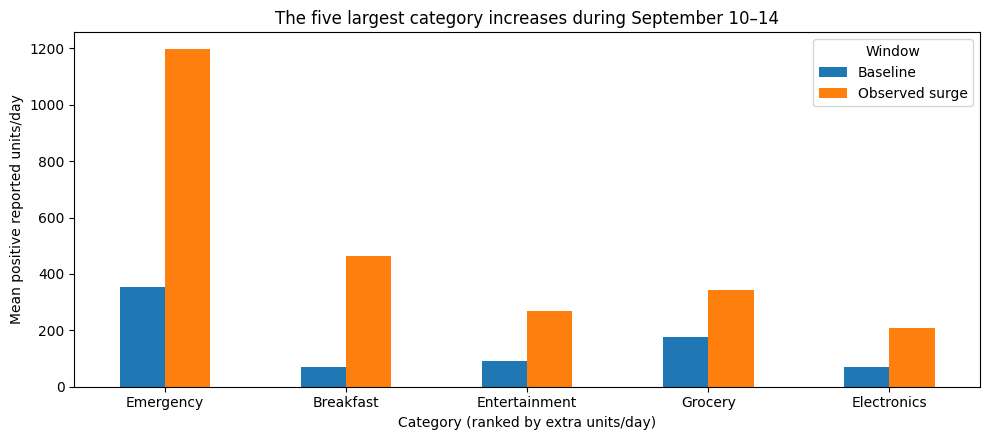

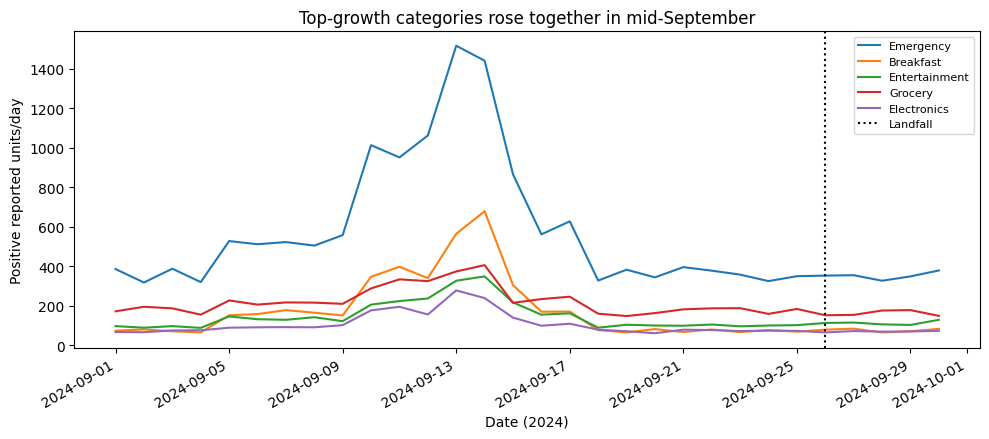

In [6]:
run_team_cells([17])

**Q1 answer, in one sentence a manager could read:** sales rose sharply in mid-September, but were near baseline in the week immediately before landfall.

### Q2 — SKU consolidation

The catalog starts with **45 distinct SKUs** and currently has **42 provisional groups**, not 42 fully verified canonical products. Only the four-SKU Strawberry Pop-Tarts family has been consolidated so far; it is the largest mapped family. The four raw positive-unit totals (1,381, 1,255, 1,300, and 1,262) become **5,198 combined reported units**. Dated units total 5,005 and undated units total 193. Three SKUs are four-packs and one is a six-pack, so these are reported package units, not equivalent physical quantities. The code below checks preservation of both overall and dated quantities.

In [7]:
run_team_cells([5, 6, 7])
assert sku_totals.sum() == pop_sales["quantity_clean"].sum()
assert daily_fragmented["Strawberry Pop-Tarts (combined)"].sum() == pop_dated["quantity_clean"].sum()
print("Provisional groups:", catalog_progress["canonical_product"].nunique())

Starting distinct catalog SKUs: 45
SKUs mapped into Pop-Tarts family: 4
Explicitly mapped product families: 1
Provisional canonical product groups: 42
Largest consolidated group: Strawberry Pop-Tarts
SKUs in largest group: 4
Remaining unmapped SKUs: 41

Pop-Tarts SKU mapping:


,sku_clean,product_family,product_name,package_size,category_clean,pack_count
0,PT-12,Strawberry Pop-Tarts,pop-tarts strawberry,4-pack,Breakfast,4
1,SKU#459812,Strawberry Pop-Tarts,Strawberry Pop-Tart,4pk,Breakfast,4
2,POPTART-STRAW,Strawberry Pop-Tarts,Pop-Tarts Strawberry,6 pack,Breakfast,6
3,PT_STRAWBERRY,Strawberry Pop-Tarts,pop-tarts strawberry,4 pack,Breakfast,4



Package-size differences present: True
Positive reported quantities by SKU:


,quantity_sold
sku_clean,
PT-12,1381
POPTART-STRAW,1300
PT_STRAWBERRY,1262
SKU#459812,1255


Combined reported quantity: 5198
Number of mapped SKUs: 4

Quantity with valid sales dates: 5005
Quantity with missing dates: 193

Initial daily sales comparison:


sku_clean,PT-12,SKU#459812,POPTART-STRAW,PT_STRAWBERRY,Strawberry Pop-Tarts (combined)
date,,,,,
2024-09-01,16,15,24,18,73
2024-09-02,34,17,14,14,79
2024-09-03,28,8,12,22,70
2024-09-04,17,15,19,13,64
2024-09-05,33,43,31,44,151
2024-09-06,33,51,33,40,157
2024-09-07,48,50,41,38,177
2024-09-08,35,43,43,43,164
2024-09-09,32,28,30,60,150



Note: Quantities are reported SKU units, not adjusted for different package sizes.
Transactions with unmatched SKUs: 0
Transaction/category disagreements: 0

All SKU mapping checks passed!
Decision log saved.
SKU mapping saved.
Provisional groups: 42


**Q2 answer:** consolidation reveals sales hidden across four codes, and Mouad will finish reviewing the remaining catalog families.

### Q3 — Weather correlation

The code below repeats Mohamed's **live Open-Meteo archive API call** (no fallback) and validated daily join, with **30 sales days before and after** and 884 undated rows excluded. Same-day correlations use 30 days; the strongest reported rainfall lag uses 25 days (rain five days before orders, about r = 0.70), and the six-day lag uses 24 (about r = 0.66). The peak is September 14, 12 days before landfall. The API result and correlations are printed again so any refresh is visible.

weather_api_rows: 30 | source: open-meteo


,date,precipitation_sum,windspeed_10m_max,source
0,2024-09-01,3.0,18.8,open-meteo
1,2024-09-02,12.4,13.5,open-meteo
2,2024-09-03,24.9,22.8,open-meteo
3,2024-09-04,22.1,15.5,open-meteo
4,2024-09-05,23.1,15.2,open-meteo


undated rows excluded from the daily series: 884
_merge
both          30
left_only      0
right_only     0
sales days with no weather: 0


,wind_r,n_wind,rain_r,n_rain
lag_days,,,,
-7,-0.04,23,0.29,23
-6,-0.17,24,0.66,24
-5,-0.30,25,0.69,25
-4,-0.27,26,0.40,26
-3,-0.24,27,0.38,27
-2,-0.28,28,0.27,28
-1,-0.31,29,-0.00,29
0,-0.24,30,0.01,30
1,-0.26,29,-0.03,29


peak order day:       2024-09-14 | 2007 orders
baseline (Sept 1-4):  580 orders/day
peak vs baseline:     3.5 x
landfall:             2024-09-26 | days from peak to landfall: 12
strongest wind day:   2024-09-26 | 48.8 km/h
heaviest rain day:    2024-09-08 | 94.7 mm
heaviest rain to peak orders: 6 days


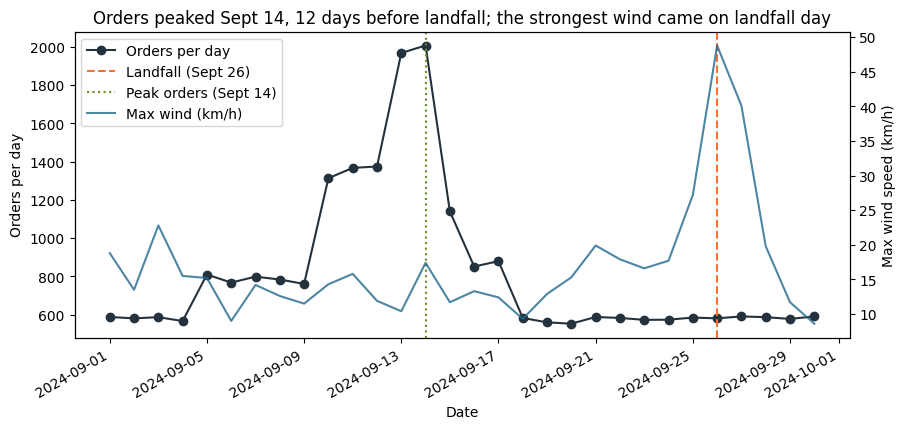

Join rows before/after: 30 30
Data source: live Open-Meteo API; no fallback
Same-day days: 30
orders               1.000000
precipitation_sum    0.010758
windspeed_10m_max   -0.237881
Name: orders, dtype: float64


In [8]:
run_team_cells([10, 12, 13])
assert weather["date"].is_unique
assert weather_merged["_merge"].eq("both").all()
assert weather_merged["date"].is_unique
assert weather_merged["orders"].sum() == weather_daily_orders["orders"].sum()
print("Join rows before/after:", len(weather_daily_orders), len(weather_merged))
print("Data source: live Open-Meteo API; no fallback")
print("Same-day days:", weather_merged[["orders", "precipitation_sum", "windspeed_10m_max"]].dropna().shape[0])
print(weather_merged[["orders", "precipitation_sum", "windspeed_10m_max"]].corr()["orders"])

**Q3 answer, with its caveat:** Sales were most strongly correlated with rainfall five days earlier (r ≈ 0.70 across 25 days), but peaked 12 days before landfall. This does not prove causation because we used only one month of Orlando weather and tested several lags.

### Q4 and Q5 — where they stand

**Q4:** Nate's completed code, two figures, and written answer are in the scratch and team notebooks; 12-store growth comparisons and 11-store distance correlations do not support stronger pre-landfall growth nearer landfall.

**Q5:** no completed inventory SQL cross-check or signal-versus-artifact answer is present in the team notebook; Mouad remains the owner and will complete it.

### Self-check

In [9]:
progress = {
    'q1_multiple': float(q1_summary.loc['Observed surge', 'multiple']),            # Computed above
    'q1_baseline_window': '2024-09-01 through 2024-09-04 inclusive',   # Inclusive baseline
    'q2_canonical_products': 42,  # Provisional, only Pop-Tarts mapped
    'q3_join_rows_preserved': len(weather_daily_orders) == len(weather_merged), # Validated above
    'q3_days_in_correlation': 25, # Five-day rain lag
    'charts_with_message_titles': 6,  # Team notebook figures
    'notebook_runs_clean': True,   # Full team notebook executed successfully
    'repo_pushed': False,           # Not pushed in this task
}

for label, value in progress.items():
    filled = not (value is None or value is False
                  or (isinstance(value, str) and value.startswith('TODO')))
    print('PASS' if filled else 'FAIL', '-', label, '=', value)
print()
print('ready for presentations:', all(
    not (v is None or v is False or (isinstance(v, str) and v.startswith('TODO')))
    for v in progress.values()))

PASS - q1_multiple = 2.9292929292929295
PASS - q1_baseline_window = 2024-09-01 through 2024-09-04 inclusive
PASS - q2_canonical_products = 42
PASS - q3_join_rows_preserved = True
PASS - q3_days_in_correlation = 25
PASS - charts_with_message_titles = 6
PASS - notebook_runs_clean = True
FAIL - repo_pushed = False

ready for presentations: False


### Write-up

**a)** One finding that surprised your team, and what you checked to make sure it was real rather than a bug.

**b)** One number you reported that you are least confident in, and why.

**a)** We were surprised that sales peaked 12 days before landfall, rather than right before the hurricane. We checked the date parsing, removed exact duplicates, and confirmed that the spike appeared across all 12 stores.

**b)** We are least confident in treating the 2.93× sales increase as a general result because our baseline covers only four days. Using a seven-day baseline lowers it to 2.49×, so the spike remains, but its size depends on the comparison window.